# ECON 422: Macroeconomics & Machine Learning
## AR, Unit Roots & ML

Explore persistence, differencing, and forecasts, then compare a classical AR model with a flexible ML model. All data are simulated; no API key or download is needed.

Our starting point is
$$
y_t=c+\phi y_{t-1}+\varepsilon_t,\qquad \varepsilon_t{\sim}N(0,1).
$$
For $|\phi|<1$, the stationary mean is $\mu=c/(1-\phi)$ and variance is $1/(1-\phi^2)$. With $c=0$ and $\phi=1$, the process is a random walk and $\Delta y_t=y_t-y_{t-1}=\varepsilon_t$.

### Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

plt.rcParams.update({"figure.figsize": (8, 3), "font.size": 11})

### Practice 1 — Same shocks, different persistence
Use the same shocks in three models, starting at $y_0=0$. These fixed-start AR paths approach stationarity; they are not initialized in the stationary distribution.

**Observe:** Which path has the longest swings? A random walk can revisit zero, but it has no restoring force toward a fixed mean.


In [3]:
rng = np.random.default_rng(28)
n = 200
shocks = rng.normal(size=n)
paths = {}

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;font-family:Menlo,Monaco,Consolas,monospace;font-size:12.5px;line-height:1.35;white-space:pre;overflow-x:auto;">
for phi in [0.4, 0.95, 1.0]:
    y = np.zeros(n + 1)
    for t in range(1, n + 1):
        y[t] = phi * y[t - 1] + shocks[t - 1]
    paths[phi] = y
    plt.plot(y, label=f&quot;phi = {phi}&quot;)
</pre>


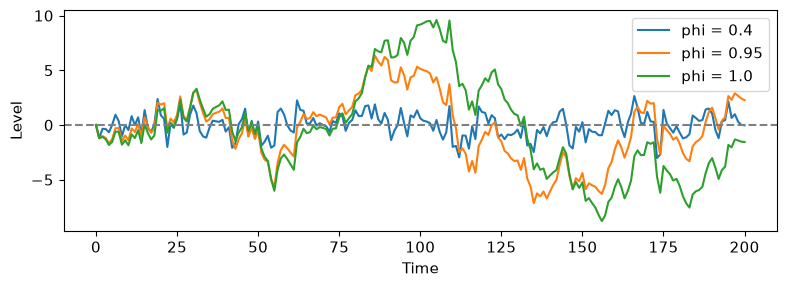

In [6]:
# Type the gray code above here.
for phi in [0.4, 0.95, 1.0]:
    y = np.zeros(n + 1)
    for t in range(1, n + 1):
        y[t] = phi * y[t - 1] + shocks[t - 1]
    paths[phi] = y
    plt.plot(y, label=f"phi = {phi}")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Level")
plt.legend()
plt.tight_layout()
plt.show()

### Practice 2 — Difference a random walk
`np.diff(y)` computes successive differences. Compare the sample lag-one correlations of the random-walk level and its changes.

**Observe:** Differencing recovers the simulated shocks. A large sample autocorrelation alone does not prove that a series has a unit root.


<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;font-family:Menlo,Monaco,Consolas,monospace;font-size:12.5px;line-height:1.35;white-space:pre;overflow-x:auto;">rw = paths[1.0]
dy = np.diff(rw)

for label, values in [(&quot;Level&quot;, rw), (&quot;Difference&quot;, dy)]:
    corr = np.corrcoef(values[:-1], values[1:])[0, 1]
    print(f&quot;{label}: lag-one correlation = {corr:.3f}&quot;)
</pre>


In [7]:
# Type the gray code above here.
rw = paths[1.0]
dy = np.diff(rw)

for label, values in [("Level", rw), ("Difference", dy)]:
    corr = np.corrcoef(values[:-1], values[1:])[0, 1]
    print(f"{label}: lag-one correlation = {corr:.3f}")

Level: lag-one correlation = 0.974
Difference: lag-one correlation = 0.017


Differences equal shocks: True


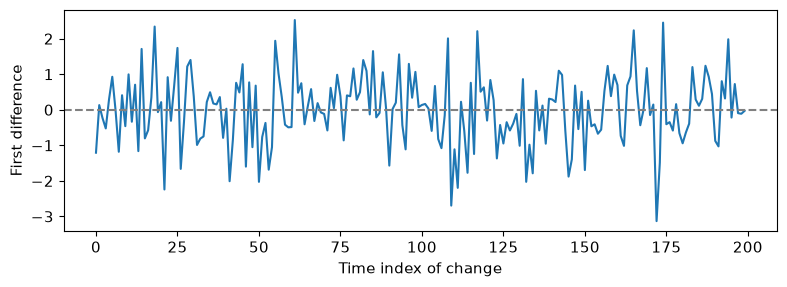

In [8]:
print("Differences equal shocks:", np.allclose(dy, shocks))
plt.plot(dy)
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Time index of change")
plt.ylabel("First difference")
plt.tight_layout()
plt.show()

### Practice 3 — Forecasts and uncertainty
Start both forecasts from $y_T=15$. For the stationary model, use $c=2$, $\phi=0.8$, and $\mu=10$; for the random walk, use zero drift. Both have shock variance $\sigma^2=1$.

$$
\widehat y_{T+h\mid T}=\mu+\phi^h(y_T-\mu),\qquad
V_h=\frac{1-\phi^{2h}}{1-\phi^2}.
$$
For the random walk, $\widehat y_{T+h\mid T}=y_T$ and $V_h=h$. Plot 95% prediction intervals as $\widehat y_{T+h\mid T}\pm1.96\sqrt{V_h}$.

**Observe:** Which forecast returns to a mean? Which band keeps widening? These formulas assume known parameters and Gaussian innovations.


<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;font-family:Menlo,Monaco,Consolas,monospace;font-size:12.5px;line-height:1.35;white-space:pre;overflow-x:auto;">h = np.arange(1, 21)
phi, mu, last = 0.8, 10.0, 15.0
ar_forecast = mu + phi**h * (last - mu)
ar_variance = (1 - phi**(2 * h)) / (1 - phi**2)
rw_forecast = np.full(len(h), last)
rw_variance = h

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, forecast, variance, title in zip(
    axes, [ar_forecast, rw_forecast],
    [ar_variance, rw_variance], [&quot;Stationary AR(1)&quot;, &quot;Random walk&quot;]
):
    width = 1.96 * np.sqrt(variance)
    ax.plot(h, forecast)
    ax.fill_between(h, forecast - width, forecast + width, alpha=0.2)
    ax.set(title=title, xlabel=&quot;Forecast horizon&quot;)
</pre>


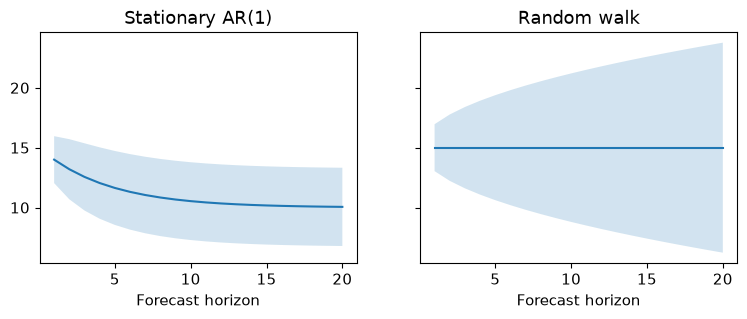

In [9]:
# Type the gray code above here.
h = np.arange(1, 21)
phi, mu, last = 0.8, 10.0, 15.0
ar_forecast = mu + phi**h * (last - mu)
ar_variance = (1 - phi**(2 * h)) / (1 - phi**2)
rw_forecast = np.full(len(h), last)
rw_variance = h

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, forecast, variance, title in zip(
    axes, [ar_forecast, rw_forecast],
    [ar_variance, rw_variance], ["Stationary AR(1)", "Random walk"]
):
    width = 1.96 * np.sqrt(variance)
    ax.plot(h, forecast)
    ax.fill_between(h, forecast - width, forecast + width, alpha=0.2)
    ax.set(title=title, xlabel="Forecast horizon")

In [10]:
axes[0].axhline(mu, color="gray", linestyle="--")
axes[0].set_ylabel("Forecast and 95% prediction interval")
plt.tight_layout()
plt.show()
print("First three AR forecasts:", np.round(ar_forecast[:3], 2))

<Figure size 800x300 with 0 Axes>

First three AR forecasts: [14.   13.2  12.56]


### Practice 4 — A simple DML example for time series
We want to estimate the effect of $d_t$ on $y_t$, controlling for $x_t$:
$$
x_t=0.6x_{t-1}+u_t,\qquad d_t=x_t+\xi_t,\qquad y_t=2d_t+x_t+\varepsilon_t.
$$
The true effect is **2**. All shocks are independent standard normal draws, and $x_t$ starts in its stationary distribution.

The three conditions hold **by construction**:

1. **Stationarity and weak dependence:** $|0.6|<1$, so dependence in $x_t$ fades over time.
2. **Time reversibility:** the stationary Gaussian AR state and independent shocks are jointly reversible; the equations use only same-date values.
3. **Conditional stability:** after controlling for $x_t$, the shocks in $d_t$ and $y_t$ are independent of observations at other dates. There is no feedback into future $x_t$.

**DML in two steps:** predict $y$ and $d$ from $x$ using the other half of the sample; regress the remaining part of $y$ on the remaining part of $d$. Repeat with the halves swapped and average the two slopes. We use linear regression as the simplest nuisance learner because this example is linear. Reordering training rows does not change its fit; use of later data is justified by this DGP.

In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Generate a simple time series; the true effect is 2.
rng = np.random.default_rng(42)
n, phi = 1000, 0.6
x = np.empty(n)
x[0] = rng.normal(scale=1 / np.sqrt(1 - phi**2))
for t in range(1, n):
    x[t] = phi * x[t - 1] + rng.normal()
xi, eps = rng.normal(size=(2, n))
d = x + xi
y = 2 * d + x + eps
X = x.reshape(-1, 1)

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;font-family:Menlo,Monaco,Consolas,monospace;font-size:12.5px;line-height:1.35;white-space:pre;overflow-x:auto;"># 2. DML: train on one half, estimate on the other; then swap.
first, second = np.array_split(np.arange(n), 2)
estimates = []
for train, test in [(second[::-1], first), (first, second)]:
    model_y = LinearRegression().fit(X[train], y[train])
    model_d = LinearRegression().fit(X[train], d[train])
    y_res = y[test] - model_y.predict(X[test])
    d_res = d[test] - model_d.predict(X[test])
    estimates.append(np.dot(d_res, y_res) / np.dot(d_res, d_res))


In [12]:
# Type the gray code above here.
first, second = np.array_split(np.arange(n), 2)
estimates = []
for train, test in [(second[::-1], first), (first, second)]:
    model_y = LinearRegression().fit(X[train], y[train])
    model_d = LinearRegression().fit(X[train], d[train])
    y_res = y[test] - model_y.predict(X[test])
    d_res = d[test] - model_d.predict(X[test])
    estimates.append(np.dot(d_res, y_res) / np.dot(d_res, d_res))

In [13]:
print("Fold estimates:", np.round(estimates, 3))
print("DML estimate:", round(np.mean(estimates), 3), "| True effect: 2")

Fold estimates: [1.956 1.983]
DML estimate: 1.97 | True effect: 2


### Exercise — Does flexibility improve the forecast?
You have a simulated series `y_ex` of length 301. Use the first 200 **lag–target pairs** for training and the remaining 100 for testing.

Fit an AR(1) by linear regression and a random forest using the same predictor $y_{t-1}$. Compare their test mean squared errors with the last-value benchmark $\widehat y_t=y_{t-1}$:
$$
\operatorname{MSE}=\frac{1}{n_{\mathrm{test}}}\sum_{t\in\mathcal T_{\mathrm{test}}}(y_t-\widehat y_t)^2.
$$

Which model has the lowest test MSE? Explain why extra flexibility need not help, and why we preserve time order.

#### DGP
The exercise uses $y_t=2+0.8y_{t-1}+\varepsilon_t$ with independent $N(0,1)$ shocks and stationary initialization. Its conditional mean is exactly linear, so the AR model has the correct functional form.


In [15]:
# Copy and paste from Quizzes '[Week10] (Oct28) Exercise'.
rng_ex = np.random.default_rng(7)
n_ex = 300
phi_ex, c_ex = 0.8, 2.0
mu_ex = c_ex / (1 - phi_ex)
y_ex = np.empty(n_ex + 1)
y_ex[0] = rng_ex.normal(mu_ex, 1 / np.sqrt(1 - phi_ex**2))
for t in range(1, n_ex + 1):
    y_ex[t] = c_ex + phi_ex * y_ex[t - 1] + rng_ex.normal()

In [16]:
X = y_ex[:-1].reshape(-1, 1)
target = y_ex[1:]
cut = 200
X_train, X_test = X[:cut], X[cut:]
y_train, y_test = target[:cut], target[cut:]

ar = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(
    n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=7
).fit(X_train, y_train)

predictions = {
    "AR(1)": ar.predict(X_test),
    "Random forest": rf.predict(X_test),
    "Last value": X_test[:, 0]
}
mse = {}
for name, pred in predictions.items():
    mse[name] = np.mean((y_test - pred) ** 2) # Average squared forecast errors on test dates only
    print(f"{name}: test MSE = {mse[name]:.3f}")

best = min(mse, key=mse.get) # Identify the dictionary key with the smallest score
print("Lowest test MSE:", best)
print(f"Estimated c = {ar.intercept_:.3f}, phi = {ar.coef_[0]:.3f}")


AR(1): test MSE = 1.045
Random forest: test MSE = 1.152
Last value: test MSE = 1.128
Lowest test MSE: AR(1)
Estimated c = 1.851, phi = 0.801
